# Descriptive statistics: common pdf and CDF

- [Some very common Univariate distributions](#Some-very-common-distributions:)
    * [Bernoulli distribution](#Bernoulli)
    * [Uniform distribution](#Uniform-distribution)
    * [Binomial distribution](#Binomial)
    * [Hypergeometric distribution](#Hypergeometric)
    * [Poisson distribution](#Poisson-distribution)
    * [Geometric distribution](#Geometric-distribution)
    * [Gaussian distribution](#Gaussian-or-normal-distribution)
    * [Chi2 distribution](#chi2)
    * [Student's distribution](#Student's-distribution)

- [References and supplementary material](#X.-References-and-supplementary-material:)

In [1]:
# Modules to be used in this notebook
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt
%matplotlib inline
from ipywidgets import interact     # for the interactive plots below (if ipywidgets is not installed, see the
                                    # cells "Run this command if ipywidget does not work")

# Our random number generator. The seed (10) is fixed so that everybody gets the same numbers.
# Change the seed (or call np.random.default_rng() without argument) to see the impact.
rng = np.random.default_rng(10)

In [2]:
# Some function for nice interactive pdf-CDF plot
def plot_dist(x, n, continuous=True, distname=''):
    """
    x : np.array
        values of the random variable at which the pdf/pmf and the CDF are evaluated
    n : scipy.stats distribution
        (frozen) distribution object
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.))
    if continuous:
        density = n.pdf
        title = "Probability Density Function (pdf)"
        plot_symbol = '-'
    else:
        density = n.pmf
        title = "Probability Mass Function (pmf)"
        plot_symbol = 'o'

    distribution = density(x)
    ax1.plot(x, distribution, plot_symbol, color="blue", label=distname)
    if continuous:
        ax1.fill_between(x, 0, distribution, color="blue", alpha=0.6)
    else:
        ax1.vlines(x, 0, distribution, colors='b', lw=5, alpha=0.5)
    ax1.set_title(title)

    if distname == 'gauss':
        # Plot mean and sigma for gaussian
        x1, x2, x3 = n.mean(), n.mean() - n.std(), n.mean() + n.std()
        ax1.vlines(x1, 0, n.pdf(x1), color='black')
        ax1.vlines(x2, 0, n.pdf(x2), color='red')
        ax1.vlines(x3, 0, n.pdf(x3), color='red')

        # The CDF at the mean is 0.5 and the CDF at mean +/- 1 sigma is 0.5 +/- 0.3413
        ax2.hlines(0.5, min(x), n.mean())
        ax2.vlines(n.mean(), 0, 0.5)
        ax2.hlines(0.5 - 0.3413, min(x), n.mean() - n.std(), color='red')
        ax2.vlines(n.mean() - n.std(), 0, 0.5 - 0.3413, color='red')
        ax2.hlines(0.5 + 0.3413, min(x), n.mean() + n.std(), color='red')
        ax2.vlines(n.mean() + n.std(), 0, 0.5 + 0.3413, color='red')

    cdf = n.cdf(x)
    if continuous:
        ax2.plot(x, cdf, lw=1, color="blue", label=distname)
        ax2.fill_between(x, 0, cdf, color="blue", alpha=0.6)
    else:
        ax2.vlines(x, 0, cdf, colors='b', lw=5, alpha=0.5)
    ax2.set_title("Cumulative Distribution Function (CDF)")

    return ax1, ax2

# Note, this function is adapted from Daniela Huppenkothen and Fernando Perez
# https://github.com/dhuppenkothen/ClassicalStatsPython

# Some very common distributions:

Relationship between common pdfs

![CommonPDF](../Figures/Common_PDF.png)

### TOC:

There are a lot of distributions and you may sometimes wonder how to choose one to describe your data ... If you keep in mind some examples of phenomena associated with common distributions, you'll more easily identify which distribution is relevant for your science case.

* **[Bernoulli distribution](#Bernoulli)**: This is the distribution you get when you toss a coin. In an astrophysical context, this can be whether an object is a member of a given class (e.g. star vs galaxy).
* **[Uniform distribution](#Uniform-distribution)**: This is the natural expansion of Bernoulli. Instead of 2 values (0,1), you have an ensemble of equally likely values: e.g. you throw a die (instead of a coin). You can *generalise* to **continuous** uniform distributions. The projected position angle of galaxies on the sky generally follows a uniform distribution.
* **[Binomial distribution](#Binomial)**: This is the distribution of the *number of successes* among $n$ independent Bernoulli trials, e.g. the number of heads in $n$ coin tosses (e.g. P(3 heads) among $n$ tosses), or the number of exoplanets detected among a set of $n$ stars.
* [Hypergeometric distribution](#Hypergeometric): Cousin of the binomial. Finite population, NO replacement.
* **[Poisson distribution](#Poisson-distribution)**: limit of the binomial for a large number of trials with a low probability of success, i.e. for rare events! This is the distribution you have when you collect photons with your telescope: many are sent but only a few are collected. This is also the case when you collect particles resulting from a radioactive decay.
* [Geometric distribution](#Geometric-distribution): Related to Bernoulli. How many trials do I need to get the first success? E.g. a coin that you flip until you get a head; or, knowing the probability to observe a transit when observing a star, what is the probability that the first transit is found at the 2nd star. Knowing that 1 QSO out of 800 is lensed, what is the probability that the first lens is found at the 100th QSO that I observe?
* **[Gaussian distribution](#Gaussian-or-normal-distribution)**: Many random variables end up being distributed following a gaussian distribution, because of the central limit theorem ... but be careful with abusive interpretation of this theorem (we'll rediscuss the central limit theorem in a future lecture).
* **[Chi2 distribution](#chi2)**: this is the distribution followed by the sum of the squares of $k$ independent *standard* normally distributed (i.e. $\mathcal{N}(0,1)$) random variables.
* **[Student's distribution](#Student's-distribution)**: distribution that arises when you standardise the mean of a small sample drawn from a gaussian distribution using an *estimate* of its standard deviation. This is important when you want to quote uncertainties on a mean with some confidence.

## Bernoulli

This is a distribution defined by a single parameter $p$. There are only *two* possible outcomes to the experiment: success or failure.

$$
{\rm Ber}(k \,|\, p)\,=\,p^k\,(1-p)^{1-k}  ~~~~ \rm{for}~k~\rm{in}~\{0,1\}
$$

Parameter: $p$ : Probability of the trial being successful

Expectation: $p$

Standard Deviation: $\sqrt{p\,(1-p)}$

**Example:** The best example of a Bernoulli trial is a coin toss (fair or unfair). In an astrophysical context, this can be whether an object is a member of a given class (e.g. star vs galaxy): the object has a probability $p$ to be in one class and $1-p$ to be in the other, depending on the relative proportion of objects in each class.

This is a *discrete* distribution for a *random variable* $k$ (that takes 2 values: 1 (success) or 0 (failure)).

In [3]:
def bernoulli(p):
    n = scipy.stats.bernoulli(p)
    x = np.linspace(0, 1, 2)      # the 2 possible values: 0 and 1
    plot_dist(x, n, continuous=False)
    plt.show()
    return

interact(bernoulli, p=(0, 1.));    # comment if ipywidget is not installed / does not work

interactive(children=(FloatSlider(value=0.5, description='p', max=1.0), Output()), _dom_classes=('widget-inter…

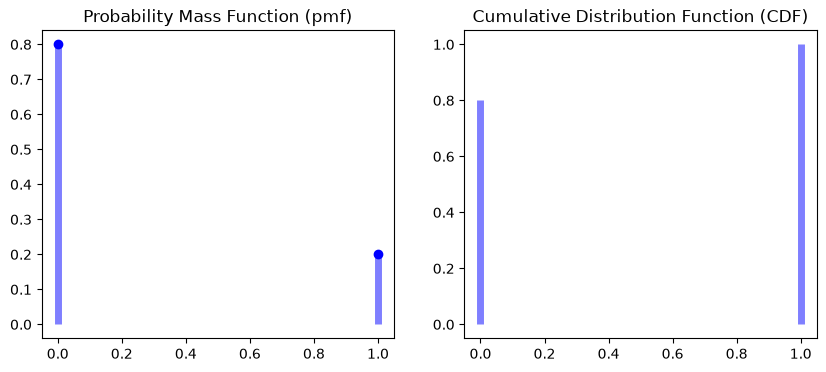

In [4]:
bernoulli(0.2)   # Run this command if ipywidget does not work - modify params

### Uniform distribution

$$
p(x \, | \, \mu, W) = \frac{1}{W} ~ \mathrm{for}~|x-\mu| \leq \frac{W}{2}, ~\mathrm{and~0~otherwise}
$$

**Parameters:** $\mu$ (centre), $W$ (width)

Expectation: $\mu$

Standard Deviation: $W / \sqrt{12}$

**Examples:** Throw a (fair) die (*discrete* uniform distribution).
In astrophysics we more commonly encounter continuous uniform distributions. For instance the projected distribution of the position angle of galaxies on the sky can be uniform between $0^o$ and $180^o$ (unless large scale structures or gravitational lensing play a role).

**Note on the `scipy.stats` parametrisation:** `scipy.stats.uniform(loc, scale)` is defined by its *left edge* `loc` and its *width* `scale`: with the notation above, `loc` $= \mu - W/2$ and `scale` $= W$ (`loc` is **not** the mean here!).

For the *discrete* version, `scipy.stats.randint(low, high)` takes the integers from `low` to `high - 1` (the upper bound is **excluded**, as in `rng.integers`). With $W$ consecutive integer values, the mean is `low` $+ (W-1)/2$ and the standard deviation is $\sqrt{(W^2-1)/12}$, which tends to $W/\sqrt{12}$ for large $W$.

In [5]:
# Discrete version of the uniform distribution (that takes only integer random variables)
def uniform_dist(low, W):
    x = np.arange(-10, 21)               # integers over which we evaluate the pmf
    n = scipy.stats.randint(low, low + W)   # W consecutive integers: low, low+1, ..., low+W-1
    plot_dist(x, n, continuous=False)
    plt.show()
    print('mean = %.2f, std = %.2f (W/sqrt(12) = %.2f)' % (n.mean(), n.std(), W / np.sqrt(12)))
    return

interact(uniform_dist, low=(-10, 10), W=(1, 10));  # comment if ipywidget is not installed / does not work
# uniform_dist(2, 4)   # Run this command if ipywidget does not work - modify params

interactive(children=(IntSlider(value=0, description='low', max=10, min=-10), IntSlider(value=5, description='…

In [6]:
# Continuous version
def uniform(mu, W):
    x = np.linspace(-10, 20, 2000)
    n = scipy.stats.uniform(mu - W/2., W)   # first argument (loc) is the LEFT EDGE, second (scale) is the width
    plot_dist(x, n)
    plt.show()
    return

interact(uniform, mu=(-10., 10.), W=(0.001, 10.0));  # comment if ipywidget is not installed / does not work
# uniform(2, 4)   # Run this command if ipywidget does not work - modify params

interactive(children=(FloatSlider(value=0.0, description='mu', max=10.0, min=-10.0), FloatSlider(value=5.00050…

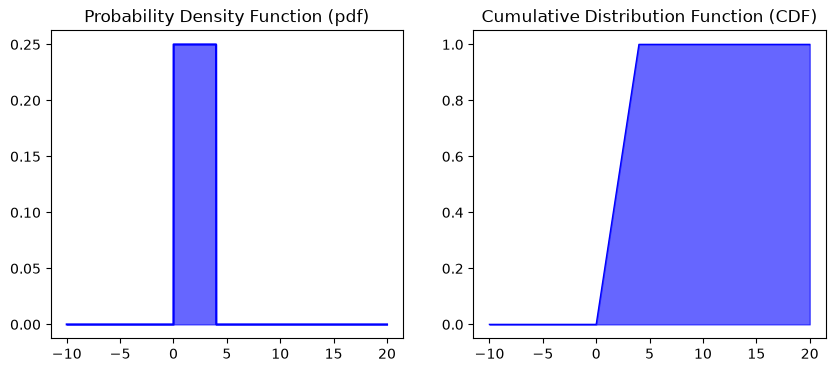

In [7]:
uniform(2, 4)

### Binomial

A binomial random variable is the sum of the outcomes of $n$ independent trials that each follow the same Bernoulli distribution.

$$
B(k\,|\,n\,,p) = \binom{n}{k}p^k(1-p)^{n-k} = \frac{n!}{k!\,(n-k)!}\,p^k\,(1-p)^{(n-k)}
$$

**Parameters**:

* $n$ : Number of trials
* $p$ : Probability of a trial being successful

Expectation: $np$

Standard Deviation: $\sqrt{n\,p\,(1-p)}$

This is a *discrete* distribution for a *variable* $k$ that takes the integer values $0, 1, \dots, n$. Each trial has only *two possible outcomes* (success/failure; event happening/event not happening, ...) and the binomial distribution $B(k|n,p)$ gives the probability of getting $k$ successes among the $n$ trials.

**Example:**
- Toss a fair coin $n$ times: how many times do you get a head (success = 1)?
- Urn with a fraction $p$ of white balls and $1-p$ of black balls, draws *with replacement*: how many white balls among $n$ draws?
- Pick galaxies on the sky: elliptical-type / other type. You know the fraction of ellipticals (e.g. $p=0.2$). What is the chance, if you observe 10 galaxies at random, to observe 0, 1, 2, ... ellipticals? The answer is given by the binomial distribution.
- Pick stars in the sky with a certain probability of hosting an exoplanet. What is the chance, if you observe 10 stars, to observe 1, 2, 3, ... $n$ exoplanets?

**Note 1**: If $n=1$, we find back the *Bernoulli* distribution.

**Note 2**: A generalisation of the binomial distribution is the multinomial distribution, if the outcome of a trial can take more than 2 values, let's say $M$ values with associated probabilities $p_1, p_2, ..., p_M$ (with $\sum_i p_i = 1$). This is called in python with `scipy.stats.multinomial(n, [p1, p2, ..., pM])`. See the example below:
``` python
# Let's consider 10 trials and 3 events A, B, C with p=(0.2, 0.5, 0.3) ; note that p_A + p_B + p_C = 1
n = 10
p = [0.2, 0.5, 0.3]  # p_A = 0.2 ; p_B=0.5 ; p_C = 0.3
d = scipy.stats.multinomial(n, p)  # Frozen multinomial distribution with n=10, p=[0.2, 0.5, 0.3]
# To calculate the probability of getting 3 times A, 4 times B, and 3 times C (A+B+C=10)
x = [3, 4, 3]
Pofx = d.pmf(x)  # only 1 argument if the distribution parameters have been defined previously: you work on a specific instance of the distribution
# If you wish to plot the full PMF, you'll need to make a 3D histogram ... and generate an array of (10*10*10, 3) and for each row i you have x[i, 0]+x[i,1]+x[i,2]=10
Out: 0.0567
```

In [8]:
def binomial(n_trials, p_success):
    d = scipy.stats.binom(n_trials, p_success)
    x = np.arange(d.ppf(0.01), d.ppf(0.99) + 1)     # integers between the 1% and 99% percentiles
    plot_dist(x, d, continuous=False)
    plt.show()
    return

# n_trials = number of trials
interact(binomial, n_trials=(1, 200, 1), p_success=(0.01, 1, 0.01)); # comment if ipywidget is not installed / does not work
# binomial(10, 0.2)   # Run this command if ipywidget does not work - modify params

interactive(children=(IntSlider(value=100, description='n_trials', max=200, min=1), FloatSlider(value=0.5, des…

In [9]:
# Check the multinomial example given above
d = scipy.stats.multinomial(10, [0.2, 0.5, 0.3])
d.pmf([3, 4, 3])

np.float64(0.05670000000000003)

### Hypergeometric

This is a cousin of the binomial distribution. It describes the probability of $k$ successes (random draws for which the object drawn has a specified feature) in $n$ draws, *without replacement*, from a finite population of size $N$ that contains exactly $K$ objects with that feature, wherein each draw is either a success or a failure.

$$
{\rm Hyp}(k \,|\,N,\,K,\,n) = \frac{\binom{K}{k} \binom{N-K}{n-k} }{\binom{N}{n}}
$$

**Parameters:**

* $N$ : the population size,
* $K$ : the number of success states in the population,
* $n$ : the number of draws,

Expectation: $n \frac{K}{N}$

Standard Deviation: $\sqrt{n\,\frac{K}{N}\,\frac{N-K}{N}\,\frac{N-n}{N-1} }$

**Examples:**
- Urn with a given number of white / black balls, draws *without* replacement.
- Stars in a field: Imagine that you observe a given field of the sky with 200 stars. You know that 10 of them are O-type and your instrument allows you to obtain 100 spectra. What is the probability that 5 of the stars you observe are of the desired type? About 0.25 (see below). This is a bit different from the binomial case, where you would know that the probability for a star to be of the given type is 0.05, and would obtain 100 spectra. The difference is subtle and comes from the fact that you know that there are exactly 10 stars among the 200 that are of the given type, and that you do not observe the same star twice. This is different from saying that the probability to observe such a star is 0.05 for each independent draw.

**Note on `scipy.stats.hypergeom(M, n, N)`:** scipy uses a different naming: `M` is the population size (our $N$), `n` the number of success states in the population (our $K$) and `N` the number of draws (our $n$). The arguments are in the same order as the parameters of the formula above.

In [10]:
def hypergeom(N_pop, K_success, n_drawn):
    # N_pop: population size ; K_success: number of success states in the population ; n_drawn: number of draws
    if K_success > N_pop or n_drawn > N_pop:
        print('K_success and n_drawn cannot be larger than the population size N_pop')
        return
    d = scipy.stats.hypergeom(N_pop, K_success, n_drawn)
    x = np.arange(d.ppf(0.01), d.ppf(0.99) + 1)
    plot_dist(x, d, continuous=False)
    plt.show()
    return

interact(hypergeom, N_pop=(1, 200, 1), K_success=(0, 199, 1), n_drawn=(1, 200, 1)); # comment if ipywidget is not installed / does not work
# hypergeom(N_pop=200, K_success=10, n_drawn=100)   # Run this command if ipywidget does not work - modify params
# Try with
# N_pop = 200 ; K_success = 10 (10/200 stars of desired type), n_drawn=100 ;
# Compare with binomial using n_trials = 100, p_success = 10/200 = 0.05

interactive(children=(IntSlider(value=100, description='N_pop', max=200, min=1), IntSlider(value=99, descripti…

In [11]:
# Probability of 5 O-type stars among the 100 observed ones (200 stars in the field, 10 of O-type)
print('Hypergeometric: p(k=5) = %.3f' % scipy.stats.hypergeom(200, 10, 100).pmf(5))
# The binomial distribution with n=100 and p=10/200=0.05 gives something different
print('Binomial:       p(k=5) = %.3f' % scipy.stats.binom(100, 0.05).pmf(5))

Hypergeometric: p(k=5) = 0.252
Binomial:       p(k=5) = 0.180


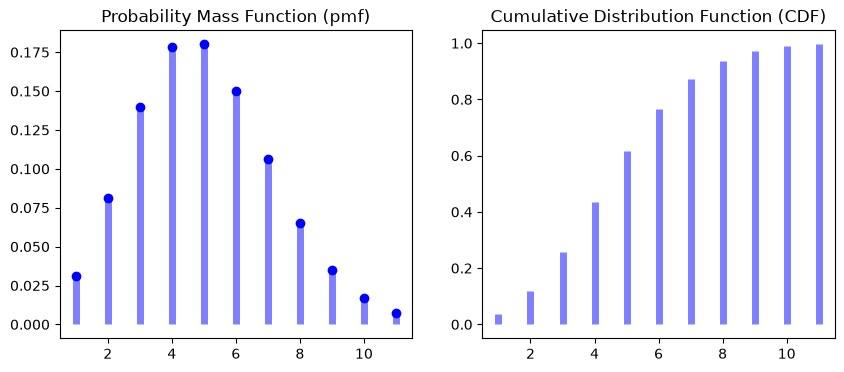

In [12]:
binomial(100, 0.05)

## Poisson distribution

This is the limit of the binomial distribution when the number $n$ of trials goes to infinity and the probability $p$ of success goes to zero (rare events), while the expected number of successes $\mu = n\,p$ remains fixed.

$$
\rm{Pois}(k\,|\,\mu) = \frac{\mu^ke^{-\mu}}{k!}
$$

**Parameters:** $\mu$ - Expected number of (random) events

Expectation: $\mu$

Standard Deviation: $\sqrt{\mu}$

**Example**: This is an important distribution in astronomy because it describes the distribution of the number of photons counted in a given interval. X-ray photons (especially of faint X-ray sources!) strictly follow a Poisson distribution. When there are many photons, the distribution becomes close to a gaussian $\mathcal{N}(\mu, \sqrt{\mu})$. You can identify the trials with the photons sent (in all directions) but we collect only a few of them. In fact we can say that photons arrive at a rate $\lambda$ $\Rightarrow$ if I integrate over a time $t$, I measure $\mu = \lambda\, t$ photons. The standard deviation is thus $\sqrt{\mu} = \sqrt{\lambda\, t}$. Hence, in a photon-limited case you have a Signal to Noise ratio: $\frac{S}{N} = \frac{\mu}{\sqrt{\mu}} = \sqrt{\mu} \propto \sqrt{t}$. If you want to double your Signal to Noise Ratio (S/N or SNR), you'll need to multiply your exposure time by 4. If you observe faint objects, you may instead be limited by the read-out noise or by the background, and the S/N then grows differently with the exposure time.

**Note:** A famous historical application of the Poisson distribution is the study by Bortkiewicz (1898) of the number of Prussian cavalry soldiers killed per year by the kick of a horse, a relatively rare event. (The distribution is named after Siméon Denis Poisson, who derived it in 1837 in the context of court judgments.)

In [13]:
def poisson(m):
    d = scipy.stats.poisson(m)
    x = np.arange(d.ppf(0.01), d.ppf(0.99) + 1)
    plot_dist(x, d, continuous=False)
    plt.show()
    return

interact(poisson, m=(1, 20, 1));  # comment if ipywidget is not installed / does not work
# poisson(10)   # Run this command if ipywidget does not work - modify params

interactive(children=(IntSlider(value=10, description='m', max=20, min=1), Output()), _dom_classes=('widget-in…

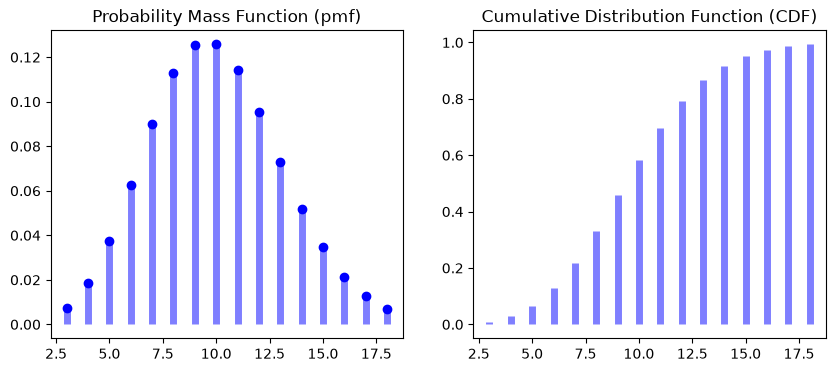

In [14]:
# Compare with a binomial for which the probability is small.
# Consider a low probability, e.g. 0.01 ; What sample size do you need to compare to a Poisson(10)?
# n * p = mu = 10  =>  n = 1000
binomial(1000, 0.01)

In [15]:
# Quantitative comparison of the binomial B(k | 1000, 0.01) and the Poisson Pois(k | 10)
k = np.arange(0, 30)
print('Largest difference between the 2 pmf: %.4f (the maximum of the pmf is %.3f)' % (
    np.abs(scipy.stats.binom(1000, 0.01).pmf(k) - scipy.stats.poisson(10).pmf(k)).max(), scipy.stats.poisson(10).pmf(k).max()))

Largest difference between the 2 pmf: 0.0006 (the maximum of the pmf is 0.125)


## Geometric distribution

The probability distribution of the number $k$ of Bernoulli trials needed to get the first success (the trial that gives the success is counted).

$$
{\rm Geom}(k\,|\,p) = (1-p)^{(k-1)}\,p   ~~~~~~~ {\rm{for\,}} k\,{\rm{in}}\, \{1, 2, 3, ...\}
$$

**Parameters:** $p$, the probability of a single success

Expectation: $\frac{1}{p}$

Standard Deviation: $\sqrt{\frac{1-p}{p^2}}$

**Example:**
- How many times should I flip a coin until I get a first head?
- Knowing the probability $p$ to observe a transit when observing a star, what is the probability that the first transit is found at the 2nd star I observe? It is ${\rm Geom}(2\,|\,p) = (1-p)\,p$. The probability to find at least one transit within the first 2 stars is given by the cumulative distribution function (CDF) of the geometric distribution.

In [16]:
def geometric(p):
    d = scipy.stats.geom(p)
    x = np.arange(d.ppf(0.01), d.ppf(0.99) + 1)
    plot_dist(x, d, continuous=False)
    plt.show()
    return

interact(geometric, p=(0.05, 1., 0.05));   # comment if ipywidget is not installed / does not work (p must be > 0)
# geometric(0.35)   # Run this command if ipywidget does not work - modify params

interactive(children=(FloatSlider(value=0.5, description='p', max=1.0, min=0.05, step=0.05), Output()), _dom_c…

## Gaussian or normal distribution

$$
\mathcal{N}(x \,|\, \mu, \sigma) = \frac{1}{\sqrt{2\pi\sigma^2}}e^{-\frac{1}{2}\left(\frac{x - \mu}{\sigma}\right)^2}
$$

**Parameters:**

* $\mu$ : central peak location
* $\sigma$: peak width (standard deviation)

Expectation: $\mu$

Standard Deviation: $\sigma$

In [19]:
def normal(mu, sigma):
    x = np.linspace(-10, 20, 2000)
    n = scipy.stats.norm(mu, sigma)
    plot_dist(x, n, distname='gauss')
    plt.show()
    return

interact(normal, mu=(-5., 10.), sigma=(0.001, 10.0)); # comment if ipywidget is not installed / does not work
# normal(mu=0, sigma=5)   # Run this command if ipywidget does not work - modify params

interactive(children=(FloatSlider(value=2.5, description='mu', max=10.0, min=-5.0), FloatSlider(value=5.000500…

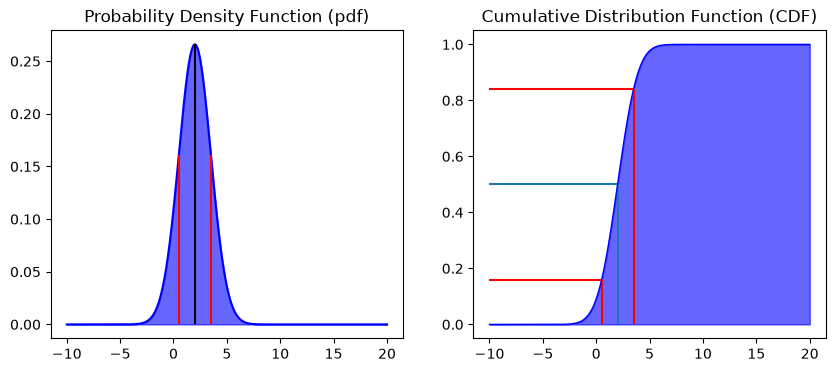

In [20]:
normal(mu=2, sigma=1.5)

### Change of variable for a normal distribution

Instead of considering a normal distribution of mean $\mu$ and width $\sigma$, one generally makes a change of variable to end up with a "canonical" gaussian pdf centred on 0, and of width $\sigma=1$, i.e. $\mathcal{N}(0,1)$.
If we write $y = (x-\mu)/\sigma$, then $y$ follows:

$$
\mathcal{N}(0,1) \, = \frac{1}{\sqrt{2\pi}} \, \exp(-0.5\,y^2)
$$

(Remember that, because densities are probabilities per unit of the variable, they transform with a Jacobian: $p_Y(y) = p_X(x(y))\,|{\rm d}x/{\rm d}y| = \sigma\,p_X(\mu + \sigma y)$, see the notebook on descriptive statistics, Part 1.)

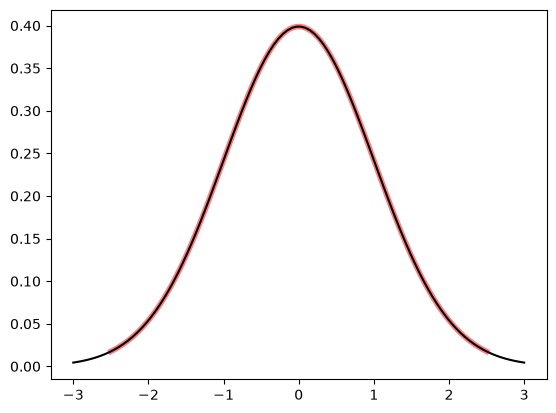

In [21]:
# Illustration: distribution of (x-\mu)/sigma
x = np.linspace(0., 10., 100)
mu, sigma = 5., 2.
y = (x - mu) / sigma
Nman = 1. / np.sqrt(2. * np.pi) * np.exp(-0.5 * y**2)
plt.figure()
plt.plot(y, Nman, alpha=0.5, lw=4, color='red')

x2 = np.linspace(-3., 3., 100)
n_scipy = scipy.stats.norm(0, 1)
plt.plot(x2, n_scipy.pdf(x2), color='black')
plt.show()

mean and std of x: 5.00, 2.01   mean and std of y: -0.00, 1.00


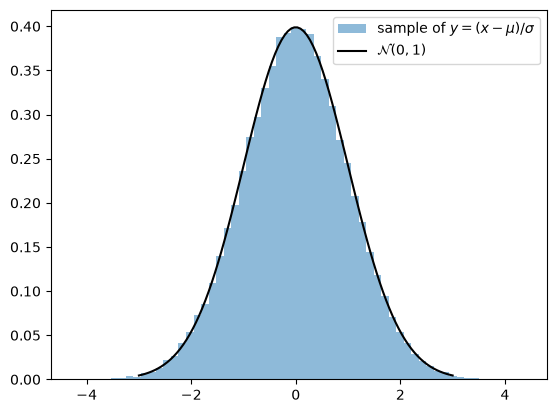

In [22]:
# Same check with random numbers: a sample drawn from N(mu, sigma), after the change of variable y = (x-mu)/sigma,
# follows a canonical gaussian N(0, 1)
x_samp = scipy.stats.norm(mu, sigma).rvs(size=100000, random_state=rng)
y_samp = (x_samp - mu) / sigma
print('mean and std of x: %.2f, %.2f   mean and std of y: %.2f, %.2f' % (x_samp.mean(), x_samp.std(), y_samp.mean(), y_samp.std()))
plt.hist(y_samp, bins=60, density=True, alpha=0.5, label='sample of $y=(x-\\mu)/\\sigma$')
plt.plot(x2, n_scipy.pdf(x2), color='black', label='$\\mathcal{N}(0,1)$')
plt.legend()

## Chi square ($\chi^2$) distribution   <a class="anchor" id="chi2"></a>

If $\{x_i\}$ are drawn from a gaussian distribution $\mathcal{N}(\mu, \sigma)$, and if we define $z_i = (x_i - \mu)/\sigma$, and
$Q = \sum_{i=1}^{k} z_i^2$, the $\chi^2$ distribution with $k$ degrees of freedom is:

$$
p(Q|k) \equiv \chi^2(Q \, |\, k) =  \frac{1} {2^{k/2}\,\Gamma(k/2)}  \, Q^{k/2-1}  \exp(-Q/2) = \frac{1} {2\,\Gamma(k/2)} \, (Q/2)^{k/2-1}  \exp(-Q/2)
$$

i.e. this is the distribution followed by the sum of the squares of $k$ independent, *standard* normally distributed (i.e. $\mathcal{N}(0,1)$) random variables.

**Parameters:** $k$  (degrees of freedom, dof)

Expectation: $k$

Standard deviation: $\sqrt{2\,k}$

Note that $\Gamma$ is the gamma function, with $\Gamma(k) = (k-1)!$ for a positive integer $k$ ($\Gamma(1/2) = \sqrt{\pi}$ for instance).

It is convenient to define the *reduced* chi-square $\chi^2_{{\rm dof}} \, \equiv \, Q/k$, which has a mean of 1 and a standard deviation $\sqrt{2 / k}$.

In [23]:
def chi2(k):
    d = scipy.stats.chi2(k)
    x = np.arange(d.ppf(0.01), d.ppf(0.99), 0.5)
    plot_dist(x, d, continuous=True)
    plt.show()
    return

interact(chi2, k=(1, 100, 1));  # comment if ipywidget is not installed / does not work
# chi2(10)   # Run this command if ipywidget does not work - modify params

interactive(children=(IntSlider(value=50, description='k', min=1), Output()), _dom_classes=('widget-interact',…

mean = 5.00 (expected k = 5), std = 3.14 (expected sqrt(2k) = 3.16)


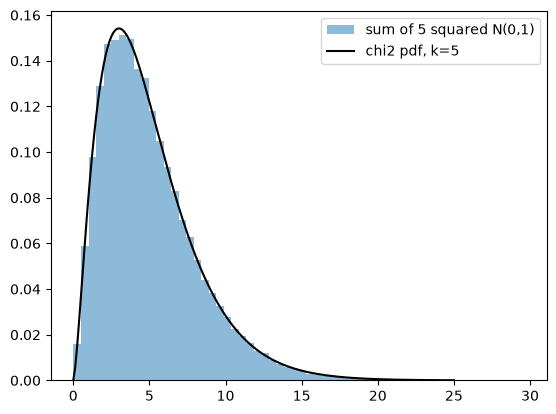

In [24]:
# Check: the sum of the squares of k standard normal variables follows a chi2 distribution with k dof
k = 5
Q = (rng.standard_normal(size=(100000, k))**2).sum(axis=1)
print('mean = %.2f (expected k = %i), std = %.2f (expected sqrt(2k) = %.2f)' % (Q.mean(), k, Q.std(), np.sqrt(2 * k)))
qq = np.linspace(0, 25, 200)
plt.hist(Q, bins=60, density=True, alpha=0.5, label='sum of 5 squared N(0,1)')
plt.plot(qq, scipy.stats.chi2(k).pdf(qq), 'k', label='chi2 pdf, k=5')
plt.legend()

## Student's distribution

$$
p(x \, | \, k) = \frac{\Gamma(\frac{k+1}{2})}{\sqrt{\pi\,k} \, \Gamma(k/2)} \, \left( 1 + \frac{x^2}{k} \right)^{-\frac{k+1}{2} },
$$

**Parameters:** $k$ $\equiv$ number of degrees of freedom (sometimes also written $\nu$).

Expectation: 0 (if $k > 1$, undefined if $k \leq 1$)

Standard deviation: $\sqrt{k/(k-2)}$ if $k > 2$ (infinite for $1 < k \leq 2$, undefined for $k \leq 1$)

If we take a sample of $N$ measurements $\{x_i\}$ drawn from a gaussian $\mathcal{N}(\mu, \sigma)$, the random variable:

$$
t = \frac{\bar{x} \,-\, \mu }{\hat{\sigma}/\sqrt{N}}
$$

follows a Student's $t(k)$ distribution with $k = N-1$ dof.

Note in the above formula, $\bar{x}$ is an estimator of the mean $\mu$ and $\hat{\sigma} = \frac{1}{\sqrt{N-1}} \sqrt{\sum_i(x_i-\bar{x})^2}$, i.e. $\hat{\sigma}$ is the *estimator* of the standard deviation.

Don't be confused! The random variable:
$$
y = \frac{\bar{x} \,-\, \mu }{\sigma/\sqrt{N}},
$$
where $\sigma$ is the "true" (population) standard deviation of the distribution, follows a normal distribution $\mathcal{N}(0, 1)$, not a Student's distribution.

**Example**: Student's distribution is useful when calculating confidence intervals on the mean of a small sample drawn from a normal distribution (i.e. when the standard deviation is not known and has to be estimated from the data). For large $k$, it tends to a normal distribution.

In [25]:
def student(k):
    d = scipy.stats.t(k)
    x = np.arange(d.ppf(0.01), d.ppf(0.99), 0.01)
    plot_dist(x, d, continuous=True)
    plt.show()
    return

interact(student, k=(1, 20, 0.5) );  # comment if ipywidget is not installed / does not work (k must be > 0)
# student(5)   # Run this command if ipywidget does not work - modify params

interactive(children=(FloatSlider(value=10.0, description='k', max=20.0, min=1.0, step=0.5), Output()), _dom_c…

In [26]:
# Check with random numbers: samples of N=5 points drawn from a gaussian N(mu=5, sigma=2)
N, mu, sigma, n_rep = 5, 5., 2., 100000
xs = rng.normal(loc=mu, scale=sigma, size=(n_rep, N))
xbar = xs.mean(axis=1)
t = (xbar - mu) / (xs.std(axis=1, ddof=1) / np.sqrt(N))   # uses the ESTIMATED std -> Student t with N-1 dof
y = (xbar - mu) / (sigma / np.sqrt(N))                     # uses the TRUE std       -> N(0, 1)
print('p(|value| > 2):  t statistic: %.3f (Student t(4): %.3f)   |   y statistic: %.3f (normal: %.3f)' % (
    np.mean(np.abs(t) > 2), 2 * scipy.stats.t(N - 1).sf(2), np.mean(np.abs(y) > 2), 2 * scipy.stats.norm.sf(2)))

p(|value| > 2):  t statistic: 0.116 (Student t(4): 0.116)   |   y statistic: 0.046 (normal: 0.046)


# X. References and supplementary material:

Chapter 3 (3.2) of the book *Statistics, data mining and Machine learning in astronomy* by Z. Ivezic et al., Princeton Series in Modern Astronomy.

Relationships between probability density distributions: http://www.math.wm.edu/~leemis/chart/UDR/UDR.html

Common PDFS: the crib sheet https://medium.com/@srowen/common-probability-distributions-347e6b945ce4

*All of statistics: a concise course in statistical inference*, Wasserman 2004 (see also errata in http://www.stat.cmu.edu/~larry/all-of-statistics/).

Numerical recipes by Press et al., Cambridge University Press: Chapter 14